lasso and regression is a use to prevent from overfitting in model

problem: predic the house price based on feature

why lasso and ridge

real -world data has:
1. too many features
2. correlated features (multicollinearity)

These models
1. reduce overfitting
2. improve accuracy

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
#load the dataset
data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print(X.head())
print(y.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: target, dtype: float64


In [ ]:
# train and split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42)

standard scaler -- convert 100 -2000 into 1-10 range for machine to understand easily

In [ ]:
# feature scaling (important for ridge & lasso)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# train ridge  regression model
ridge = Ridge()
ridge.fit(X_train_scaled, y_train)

# predict
y_pred_ridge = ridge.predict(X_test_scaled)

# evaluate

print("ridge_mse",mean_squared_error(y_test,y_pred_ridge))
print("ridge_r2",r2_score(y_test, y_pred_ridge))


ridge_mse 0.5558548589435972
ridge_r2 0.5758157428913683


In [ ]:
# lasso regression model

lasso = Lasso()
lasso.fit(X_train_scaled, y_train)

# predict
y_pred_lasso = lasso.predict(X_test_scaled)

# evaluate

print("lasso_mse",mean_squared_error(y_test,y_pred_lasso))
print("lasso_r2",r2_score(y_test, y_pred_lasso))

lasso_mse 1.3106960720039365
lasso_r2 -0.00021908714592466794


In [ ]:
what happen here lasso is showing more error so lasso is not needed in this regression

In [ ]:
# hyperparameter turning
# ridge tuning

ridge_params = {"alpha": [0.01,0.1,1,10,100]}
ridge_grid = GridSearchCV(Ridge(), ridge_params, cv=5)
ridge_grid.fit(X_train_scaled, y_train)

print("best ridge alpla:", ridge_grid.best_params_)



best ridge alpla: {'alpha': 0.01}


In [ ]:
# hyperparameter turning
# lasso tuning

lasso_params = {"alpha": [0.01,0.1,1,10,100]}
lasso_grid = GridSearchCV(Lasso(max_iter=10000), lasso_params, cv=5)
lasso_grid.fit(X_train_scaled, y_train)

print("best lasso alpla:",lasso_grid.best_params_)

best lasso alpla: {'alpha': 0.01}


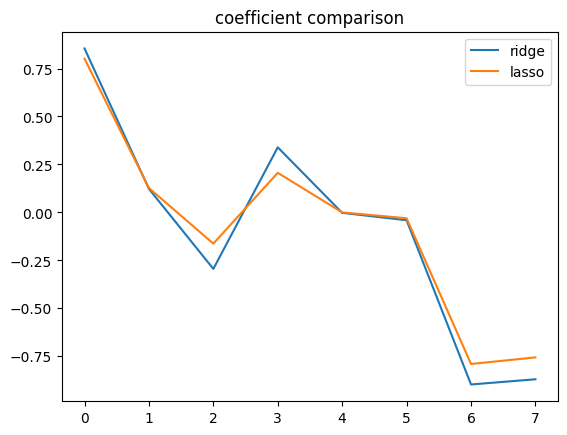

In [ ]:
#visualization :coefficients comparision

ridge_best = ridge_grid.best_estimator_
lasso_best = lasso_grid.best_estimator_

plt.figure()
plt.plot(ridge_best.coef_, label='ridge')
plt.plot(lasso_best.coef_, label='lasso')
plt.legend()
plt.title('coefficient comparison')
plt.show()

In [ ]:
whenever you need to increase the accuracy of the modela and then to improve the  overfitting